In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
# 设置绘图风格
sns.set_style("whitegrid")
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
 
# 加载数据
train_df = pd.read_csv('D:/VsCodeProjects/Kaggle/source/Titanic/competitions/titanic/train.csv')
print("数据形状:", train_df.shape)
print("\n前5行数据预览:")
print(train_df.head())

数据形状: (891, 12)

前5行数据预览:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   

In [2]:
print("\n=== 数据基本信息 ===")
print(train_df.info())
 
print("\n=== 缺失值统计 ===")
print(train_df.isnull().sum())


=== 数据基本信息 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

=== 缺失值统计 ===
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687

Age < 5 的生存率: 67.50%


C:\Users\26082\AppData\Local\Temp\ipykernel_24380\552446972.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)


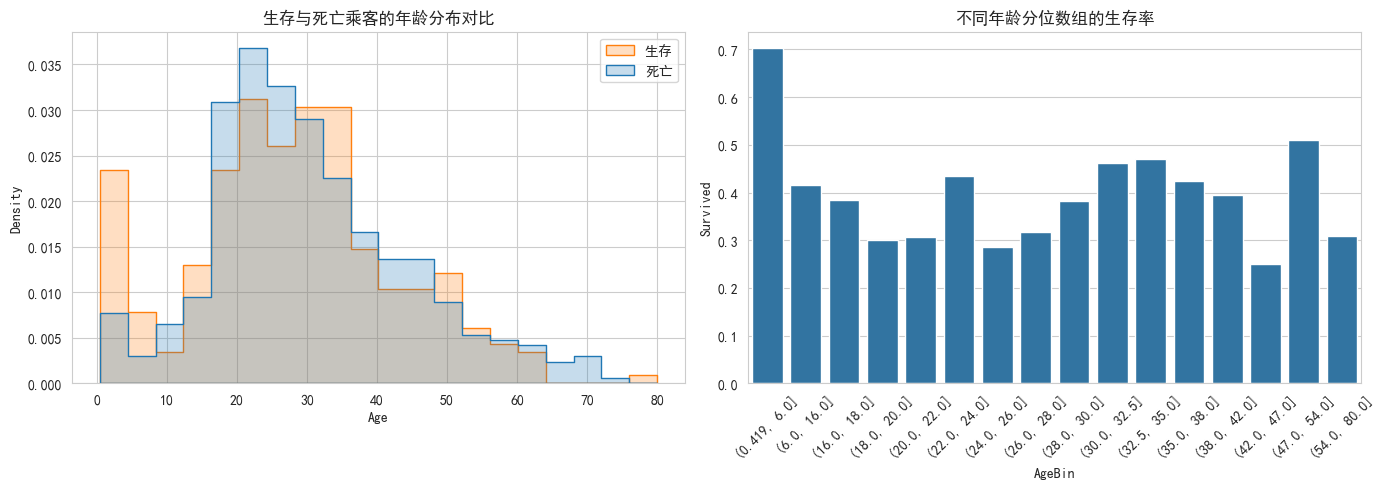

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

survival_rate = train_df.loc[train_df['Age'] < 5, 'Survived'].mean()
print(f"Age < 5 的生存率: {survival_rate:.2%}")

# 生存与未生存乘客的年龄分布对比
sns.histplot(data=train_df, x='Age', hue='Survived', element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('生存与死亡乘客的年龄分布对比')
axes[0].legend(['生存', '死亡'])
 
# 年龄分组后的生存率（使用分位数切分，避免主观分组）
train_df['AgeBin'] = pd.qcut(train_df['Age'].fillna(train_df['Age'].median()), q=20, duplicates='drop')
age_survival_rate = train_df.groupby('AgeBin', observed=False)['Survived'].mean().reset_index()
sns.barplot(data=age_survival_rate, x='AgeBin', y='Survived', ax=axes[1])
axes[1].set_title('不同年龄分位数组的生存率')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

In [15]:
survival_rate = train_df.loc[train_df['Sex'] == "female", 'Survived'].mean()
print(f"Female 的生存率: {survival_rate:.2%}")

survival_rate = train_df.loc[train_df['Sex'] == "male", 'Survived'].mean()
print(f"Male 的生存率: {survival_rate:.2%}")   

Female 的生存率: 74.20%
Male 的生存率: 18.89%



票价描述性统计:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


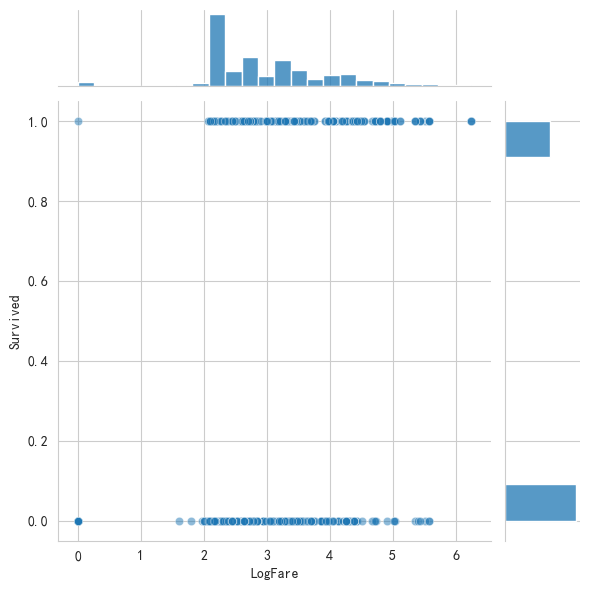

In [16]:
print("\n票价描述性统计:")
print(train_df['Fare'].describe())
 
# 票价与生存关系的散点图（由于票价分布偏斜，取对数后查看）
train_df['LogFare'] = np.log1p(train_df['Fare']) # log(1+Fare) 处理0值
sns.jointplot(data=train_df, x='LogFare', y='Survived', kind='scatter', alpha=0.5, height=6)
plt.show()

In [17]:
# 提取头衔
train_df['Title'] = train_df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
print("提取到的头衔种类:", train_df['Title'].unique())
 
# 查看各头衔的生存率
title_survival = train_df.groupby('Title')['Survived'].agg(['mean', 'count'])
print(title_survival.sort_values(by='mean', ascending=False))

提取到的头衔种类: ['Mr' 'Mrs' 'Miss' 'Master' 'Don' 'Rev' 'Dr' 'Mme' 'Ms' 'Major' 'Lady'
 'Sir' 'Mlle' 'Col' 'Capt' 'Countess' 'Jonkheer']
              mean  count
Title                    
Countess  1.000000      1
Ms        1.000000      1
Lady      1.000000      1
Mme       1.000000      1
Mlle      1.000000      2
Sir       1.000000      1
Mrs       0.792000    125
Miss      0.697802    182
Master    0.575000     40
Major     0.500000      2
Col       0.500000      2
Dr        0.428571      7
Mr        0.156673    517
Capt      0.000000      1
Don       0.000000      1
Jonkheer  0.000000      1
Rev       0.000000      6


In [18]:
# 将稀有头衔归为一类，并规范化一些头衔
title_mapping = {
    'Mr': 'Mr',
    'Miss': 'Miss',
    'Mrs': 'Mrs',
    'Master': 'Master',
    'Dr': 'Rare',
    'Rev': 'Rare',
    'Col': 'Rare',
    'Major': 'Rare',
    'Mlle': 'Miss', # 法语“小姐”
    'Ms': 'Miss',
    'Mme': 'Mrs',   # 法语“夫人”
    'Don': 'Rare',
    'Dona': 'Rare',
    'Lady': 'Rare',
    'Countess': 'Rare',
    'Sir': 'Rare',
    'Jonkheer': 'Rare',
    'Capt': 'Rare'
}
train_df['Title'] = train_df['Title'].map(title_mapping)
print("\n合并后的头衔分布及生存率:")
print(train_df.groupby('Title')['Survived'].agg(['mean', 'count']))


合并后的头衔分布及生存率:
            mean  count
Title                  
Master  0.575000     40
Miss    0.702703    185
Mr      0.156673    517
Mrs     0.793651    126
Rare    0.347826     23


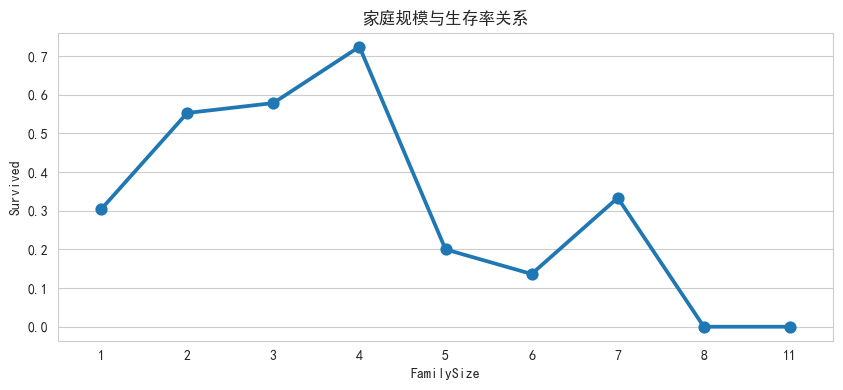

In [19]:
train_df['FamilySize'] = train_df['SibSp'] + train_df['Parch'] + 1  # 加上自己
train_df['IsAlone'] = (train_df['FamilySize'] == 1).astype(int)
 
# 查看家庭规模与生存率的关系
family_survival = train_df.groupby('FamilySize')['Survived'].mean().reset_index()
plt.figure(figsize=(10,4))
sns.pointplot(data=family_survival, x='FamilySize', y='Survived')
plt.title('家庭规模与生存率关系')
plt.show()

In [20]:
# 提取船舱首字母，缺失值用‘N’表示
train_df['Deck'] = train_df['Cabin'].apply(lambda x: x[0] if pd.notna(x) else 'N')
print("各甲板层乘客数量及生存率:")
print(train_df.groupby('Deck')['Survived'].agg(['mean', 'count']).sort_values(by='count', ascending=False))

各甲板层乘客数量及生存率:
          mean  count
Deck                 
N     0.299854    687
C     0.593220     59
B     0.744681     47
D     0.757576     33
E     0.750000     32
A     0.466667     15
F     0.615385     13
G     0.500000      4
T     0.000000      1


In [21]:
# 提取票号中的字母部分（如果有的话）
train_df['TicketPrefix'] = train_df['Ticket'].apply(lambda x: x.split()[0] if len(x.split()) > 1 else 'NONE')
# 简化：将出现次数少的前缀归为‘OTHER’
prefix_counts = train_df['TicketPrefix'].value_counts()
rare_prefixes = prefix_counts[prefix_counts < 10].index
train_df['TicketPrefix'] = train_df['TicketPrefix'].replace(list(rare_prefixes), 'OTHER')
print("常见票号前缀:", train_df['TicketPrefix'].unique()[:10])

常见票号前缀: ['A/5' 'PC' 'OTHER' 'NONE' 'C.A.' 'STON/O']


In [22]:
# 对年龄进行等频分箱（5箱）
train_df['AgeBin'] = pd.qcut(train_df['Age'], q=5, labels=False, duplicates='drop')
# 对票价进行等频分箱（考虑到偏态分布，先取对数）
train_df['FareBin'] = pd.qcut(np.log1p(train_df['Fare']), q=5, labels=False, duplicates='drop')
 
# 创建交互特征：例如，性别与舱等的组合可能比单独特征更有力
train_df['Sex_Pclass'] = train_df['Sex'] + '_' + train_df['Pclass'].astype(str)
print("性别与舱等组合的生存率:")
print(train_df.groupby('Sex_Pclass')['Survived'].mean())

性别与舱等组合的生存率:
Sex_Pclass
female_1    0.968085
female_2    0.921053
female_3    0.500000
male_1      0.368852
male_2      0.157407
male_3      0.135447
Name: Survived, dtype: float64


In [23]:
from sklearn.preprocessing import OneHotEncoder
 
# 选择需要进行独热编码的列
categorical_cols = ['Title', 'Deck', 'Embarked', 'Sex_Pclass']
# 初始化编码器，并设置handle_unknown='ignore'以应对新类别
ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
ohe_features = ohe.fit_transform(train_df[categorical_cols])
# 获取编码后的特征名称
ohe_feature_names = ohe.get_feature_names_out(categorical_cols)
# 创建编码后的DataFrame
ohe_df = pd.DataFrame(ohe_features, columns=ohe_feature_names, index=train_df.index)
 
# 将编码后的特征与原始数据合并
train_df_encoded = pd.concat([train_df.drop(columns=categorical_cols), ohe_df], axis=1)

In [24]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
 
# 假设我们仍想保留连续的‘Age’和‘Fare’用于某些模型
num_cols_to_impute = ['Age', 'Fare']
imputer = KNNImputer(n_neighbors=5)
train_df_encoded[num_cols_to_impute] = imputer.fit_transform(train_df_encoded[num_cols_to_impute])
 
# 对连续数值特征进行标准化
continuous_cols = ['Age', 'Fare', 'FamilySize']
scaler = StandardScaler()
train_df_encoded[continuous_cols] = scaler.fit_transform(train_df_encoded[continuous_cols])

In [25]:
# 计算数值特征与生存目标的相关系数
numeric_features = train_df_encoded.select_dtypes(include=[np.number]).columns.tolist()
correlation_with_target = train_df_encoded[numeric_features].corrwith(train_df_encoded['Survived']).abs().sort_values(ascending=False)
print("特征与目标变量的绝对相关系数（Top 10）:")
print(correlation_with_target.head(10))
 
# 我们可以选择相关系数高于某个阈值（例如0.05）的特征
selected_features = correlation_with_target[correlation_with_target > 0.05].index.tolist()
# 确保目标变量不在特征列表中
if 'Survived' in selected_features:
    selected_features.remove('Survived')
 
print(f"\n最终选择的特征数量: {len(selected_features)}")
print("特征列表:", selected_features)

特征与目标变量的绝对相关系数（Top 10）:
Survived               1.000000
Title_Mr               0.549199
Sex_Pclass_male_3      0.407925
Title_Mrs              0.341994
Pclass                 0.338481
Sex_Pclass_female_2    0.337329
Title_Miss             0.335636
LogFare                0.329862
FareBin                0.317783
Deck_N                 0.316912
dtype: float64

最终选择的特征数量: 22
特征列表: ['Title_Mr', 'Sex_Pclass_male_3', 'Title_Mrs', 'Pclass', 'Sex_Pclass_female_2', 'Title_Miss', 'LogFare', 'FareBin', 'Deck_N', 'Fare', 'IsAlone', 'Deck_B', 'Sex_Pclass_male_2', 'Embarked_S', 'Deck_D', 'Deck_E', 'Deck_C', 'Sex_Pclass_female_3', 'Parch', 'Embarked_nan', 'Age', 'Deck_F']


In [26]:
X = train_df_encoded[selected_features]
y = train_df_encoded['Survived']
 
print(f"特征矩阵形状: {X.shape}")
print(f"目标向量形状: {y.shape}")

特征矩阵形状: (891, 22)
目标向量形状: (891,)


In [27]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
 
# 1. 基线模型：仅使用原始特征（简单处理）
base_features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
# 对基线特征进行简单处理（填充、编码）
from sklearn.preprocessing import LabelEncoder
X_base = train_df[base_features].copy()
X_base['Age'].fillna(X_base['Age'].median(), inplace=True)
X_base['Fare'].fillna(X_base['Fare'].median(), inplace=True)
X_base['Embarked'].fillna(X_base['Embarked'].mode()[0], inplace=True)
le = LabelEncoder()
X_base['Sex'] = le.fit_transform(X_base['Sex'])
X_base = pd.get_dummies(X_base, columns=['Embarked'], drop_first=True)
 
# 2. 工程后特征（即我们上面构建的X）
X_engineered = X
 
# 使用逻辑回归进行5折交叉验证比较
lr = LogisticRegression(max_iter=1000, random_state=42)
print("=== 逻辑回归模型5折交叉验证平均准确率 ===")
base_scores = cross_val_score(lr, X_base, y, cv=5, scoring='accuracy')
print(f"基线特征: {base_scores.mean():.4f} (+/- {base_scores.std()*2:.4f})")
eng_scores = cross_val_score(lr, X_engineered, y, cv=5, scoring='accuracy')
print(f"工程后特征: {eng_scores.mean():.4f} (+/- {eng_scores.std()*2:.4f})")
 
# 使用随机森林进行同样比较
rf = RandomForestClassifier(n_estimators=100, random_state=42)
print("\n=== 随机森林模型5折交叉验证平均准确率 ===")
base_scores_rf = cross_val_score(rf, X_base, y, cv=5, scoring='accuracy')
print(f"基线特征: {base_scores_rf.mean():.4f} (+/- {base_scores_rf.std()*2:.4f})")
eng_scores_rf = cross_val_score(rf, X_engineered, y, cv=5, scoring='accuracy')
print(f"工程后特征: {eng_scores_rf.mean():.4f} (+/- {eng_scores_rf.std()*2:.4f})")

C:\Users\26082\AppData\Local\Temp\ipykernel_24380\757135900.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_base['Age'].fillna(X_base['Age'].median(), inplace=True)
C:\Users\26082\AppData\Local\Temp\ipykernel_24380\757135900.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy

=== 逻辑回归模型5折交叉验证平均准确率 ===
基线特征: 0.7912 (+/- 0.0371)
工程后特征: 0.8138 (+/- 0.0662)

=== 随机森林模型5折交叉验证平均准确率 ===
基线特征: 0.8081 (+/- 0.0477)
工程后特征: 0.8047 (+/- 0.0746)
